In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Se pide, usando regresión lineal:

Dibujar con una línea la relación que hay entre la altura y la edad de los alumnos de esta clase: 

In [3]:
lista_alumnos = [("Leonardo S", 24, 1.82), 
                 ("Piero T", 25, 1.71), 
                 ("Marta B", 35, 1.66), 
                 ("Silvia P", 37, 1.63), 
                 ("Faro Z", 29, 1.90), 
                 ("Miguel N", 27, 1.80), 
                 ("Alejandro M", 28, 1.70), 
                 ("Cristina M", 32, 1.60), 
                 ("Francisco P", 36, 1.74), 
                 ("Jorge D", 45, 1.72), 
                 ("Jesús L", 41, 1.65), 
                 ("Marta G", 30, 1.65), 
                 ("Jennifer S", 40, 1.60), 
                 ("Diego I", 39, 1.80), 
                 ("Antonio C", 23, 1.77), 
                 ("Juan M", 32, 1.75), 
                 ("David S", 27, 1.70), 
                 ("Antonio J", 34, 1.80), 
                 ("Carlos H", 27, 1.77), 
                 ("Erik U", 28, 1.70), 
                 ("Marcos L", 35, 1.80)] 

In [4]:
df = pd.DataFrame(lista_alumnos, columns=['Alumnos', 'Edad', 'Altura'])
df.head()

,Alumnos,Edad,Altura
0,Leonardo S,24,1.82
1,Piero T,25,1.71
2,Marta B,35,1.66
3,Silvia P,37,1.63
4,Faro Z,29,1.90


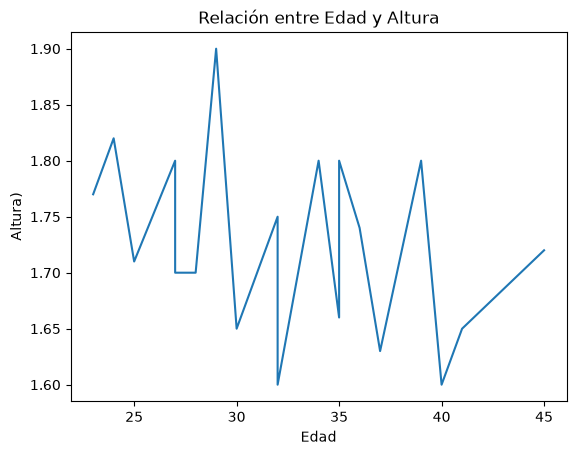

In [5]:
df_plot = df.sort_values('Edad')
plt.figure()
plt.plot(
    df_plot['Edad'],
    df_plot['Altura'],
    )

plt.title("Relación entre Edad y Altura")
plt.xlabel("Edad")
plt.ylabel("Altura)")
plt.show()

### ¿Es una buena técnica para este tipo de problemas? Demuéstralo antes de entrenar un modelo con un análisis descriptivo.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Alumnos  21 non-null     str    
 1   Edad     21 non-null     int64  
 2   Altura   21 non-null     float64
dtypes: float64(1), int64(1), str(1)
memory usage: 806.0 bytes


In [7]:
df.describe()

,Edad,Altura
count,21.000000,21.000000
mean,32.095238,1.727143
std,6.081980,0.079003
min,23.000000,1.600000
25%,27.000000,1.660000
50%,32.000000,1.720000
75%,36.000000,1.800000
max,45.000000,1.900000


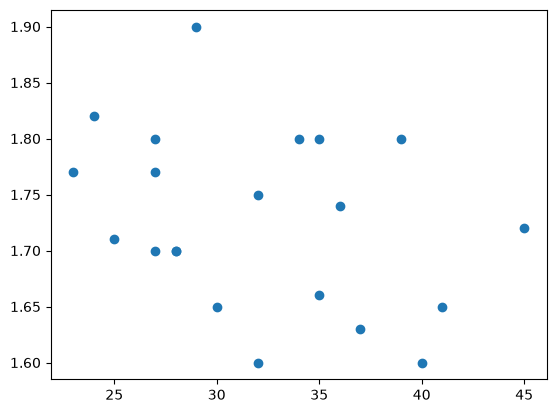

In [8]:
plt.scatter(df['Edad'], df['Altura'])
plt.show()

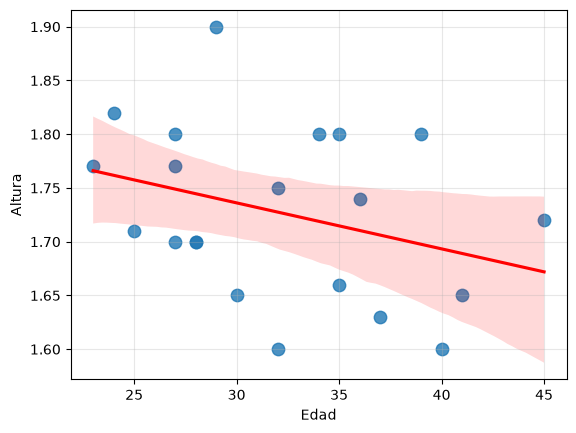

In [9]:
sns.regplot(
    data=df,
    x='Edad',
    y='Altura',
    scatter_kws={"s": 80},
    line_kws={"color": "red"}
)

plt.grid(alpha=0.3)
plt.show()

In [10]:
corr = df.corr(numeric_only=True)
corr

,Edad,Altura
Edad,1.000000,-0.329275
Altura,-0.329275,1.000000


<Axes: >

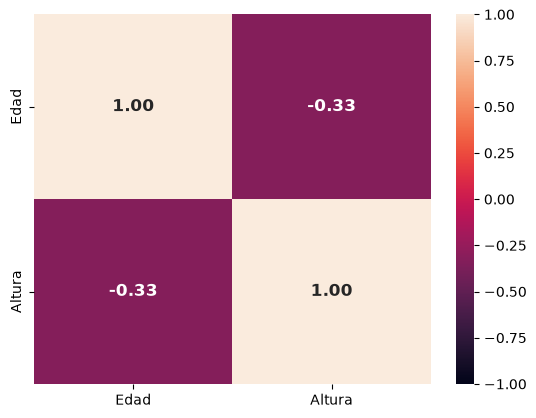

In [11]:
sns.heatmap(
    corr,
    annot=True, # que me ponga los numeros dentro
    fmt=".2f", # indica el numero de decimales
    annot_kws={"size": 12, "weight": "bold"},
    vmin=-1,
    vmax=1
)

In [12]:
df['Altura'].value_counts()

Altura
1.80    4
1.70    3
1.60    2
1.65    2
1.77    2
1.82    1
1.71    1
1.66    1
1.63    1
1.90    1
1.74    1
1.72    1
1.75    1
Name: count, dtype: int64

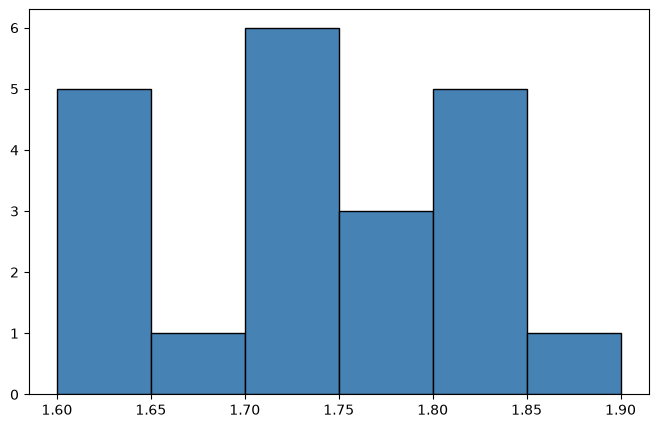

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Altura"],
    bins=6,
    color="steelblue",
    edgecolor="black"
)

plt.show()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Nombre  21 non-null     object 
 1   Edad    21 non-null     int64  
 2   Altura  21 non-null     float64
dtypes: float64(1), int64(1), object(1)
memory usage: 636.0+ bytes


,Edad,Altura
count,21.000000,21.000000
mean,32.095238,1.727143
std,6.081980,0.079003
min,23.000000,1.600000
25%,27.000000,1.660000
50%,32.000000,1.720000
75%,36.000000,1.800000
max,45.000000,1.900000


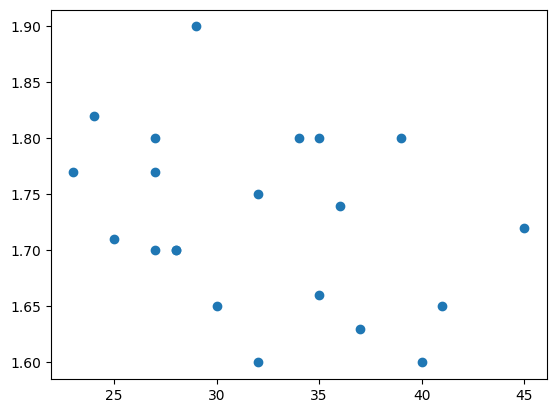

<Axes: xlabel='Edad', ylabel='Altura'>

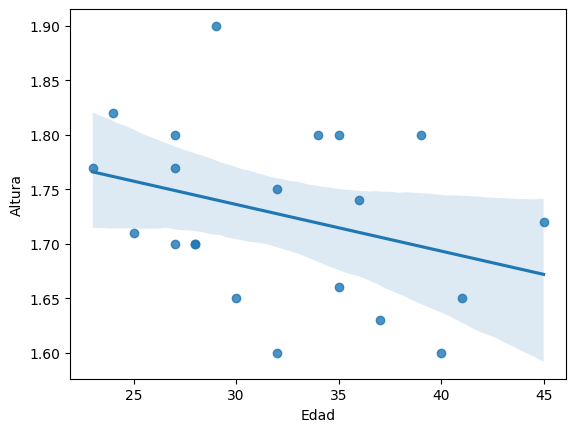

<Axes: >

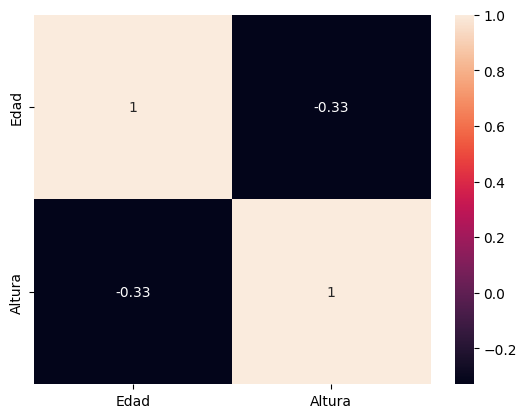

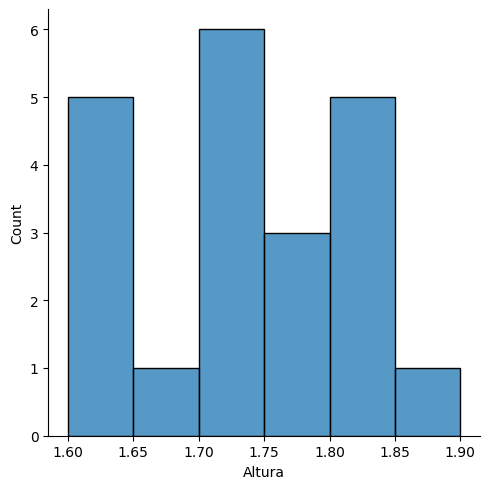

### Entrena un modelo de regresión lineal

In [46]:
df.columns

Index(['Alumnos', 'Edad', 'Altura'], dtype='str')

In [79]:
# Columns as Features
X = df[['Edad']]
X

,Edad
0,24
1,25
2,35
3,37
4,29
5,27
6,28
7,32
8,36
9,45


In [80]:
# Altura es lo que intento predecir
y = df['Altura']
y

0     1.82
1     1.71
2     1.66
3     1.63
4     1.90
5     1.80
6     1.70
7     1.60
8     1.74
9     1.72
10    1.65
11    1.65
12    1.60
13    1.80
14    1.77
15    1.75
16    1.70
17    1.80
18    1.77
19    1.70
20    1.80
Name: Altura, dtype: float64

y = a + b*X

altura = a + b*Edad

(16, 1)
(5, 1)
(16,)
(5,)


y = a + b*x

altura = a + b*Edad

In [81]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 42)
# esto me devuelve una tupla (x_train, x_test, y_train, y_test)

In [82]:
print("Total features shape:", X.shape)
print("Train features shape:", X_train.shape)
print("Train target shape:", y_train.shape)
print("Test features shape:", X_test.shape)
print("Test target shape:", y_test.shape)

Total features shape: (21, 1)
Train features shape: (16, 1)
Train target shape: (16,)
Test features shape: (5, 1)
Test target shape: (5,)


In [83]:
X_train

,Edad
5,27
11,30
3,37
18,27
16,27
13,39
2,35
9,45
20,35
4,29


In [87]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [88]:
lm.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[-0.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Edad']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,1.858
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [93]:
lm.coef_ # esto es la pendiente

array([-0.00427716])

In [90]:
lm.intercept_

np.float64(1.858051298091961)

y = a + b * x

altura = 1.86 - 0.004 * Edad

In [94]:
coeff_df = pd.DataFrame(lm.coef_,
                        X.columns,
                        columns=['Coefficient'])
coeff_df

,Coefficient
Edad,-0.004277


LinearRegression()

LinearRegression()

np.float64(1.858051298091961)

array([-0.00435721])

Altura = 1.86 - 0.004 * Edad

1.7247000000000001


c:\Users\Alberto Romero\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


array([1.72297779, 1.6837629 , 1.7709071 ])

### ¿Qué error se comete? Calcula los errores que está cometiendo tu modelo de forma manual con python. Aparte, usa las métricas de sklearn MAE, MAPE, MSE y el RMSE.

In [97]:
X_test

,Edad
0,24
17,34
15,32
1,25
8,36


In [98]:
predictions = lm.predict(X_test)
predictions

array([1.76176751, 1.71899588, 1.72755021, 1.75749035, 1.71044156])

In [104]:
y_test

0     1.82
17    1.80
15    1.75
1     1.71
8     1.74
Name: Altura, dtype: float64

In [99]:
from sklearn import metrics

lm.score(X_test, y_test)

-0.6731180187778203

In [110]:
metrics.mean_absolute_error(y_test, predictions) # MAE

0.04774703913491245

In [111]:
metrics.mean_squared_error(y_test, predictions) # MSE

0.002717143662495185

In [ ]:
np.sqrt(metrics.mean_squared_error(y_test, predictions)) # RMSE

np.float64(0.052126228162942934)

In [ ]:
metrics.root_mean_squared_error(y_test, predictions) # RMSE otra forma de hacerlo

0.052126228162942934

In [123]:
from sklearn.metrics import mean_absolute_percentage_error

In [124]:
y_pred = lm.predict(X_test)

mape = mean_absolute_percentage_error(y_test, y_pred)
mape

0.026917272158515953

In [122]:
r2 = lm.score(X_test, y_test)
r2

-0.6731180187778203

In [109]:
error = predictions - y_test
error

0    -0.058232
17   -0.081004
15   -0.022450
1     0.047490
8    -0.029558
Name: Altura, dtype: float64

In [115]:
error_cuad = error*error
error_cuad

0     0.003391
17    0.006562
15    0.000504
1     0.002255
8     0.000874
Name: Altura, dtype: float64

In [121]:
df1 = pd.DataFrame(X_test)
df1['predictions'] = predictions
df1['y_test'] = y_test
df1['error'] = error
df1['error_cuad'] = error_cuad
df1

,Edad,predictions,y_test,error,error_cuad
0,24,1.761768,1.82,-0.058232,0.003391
17,34,1.718996,1.80,-0.081004,0.006562
15,32,1.727550,1.75,-0.022450,0.000504
1,25,1.757490,1.71,0.047490,0.002255
8,36,1.710442,1.74,-0.029558,0.000874


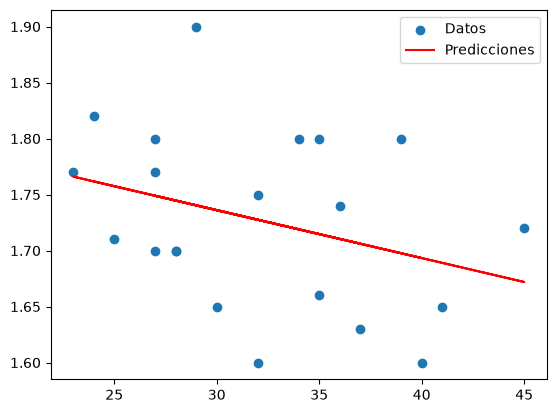

In [125]:
plt.scatter(df['Edad'], df['Altura'], label="Datos")
plt.plot(df['Edad'], lm.predict(X), color="r", label="Predicciones")
plt.legend()
plt.show()

array([1.75347826, 1.70990616, 1.71862058, 1.74912105, 1.70119174])

0     1.82
17    1.80
15    1.75
1     1.71
8     1.74
Name: Altura, dtype: float64

,Edad,prediccion,valor_real,error,error_cuad
0,24,1.753478,1.82,0.066522,0.004425
17,34,1.709906,1.80,0.090094,0.008117
15,32,1.718621,1.75,0.031379,0.000985
1,25,1.749121,1.71,0.039121,0.001530
8,36,1.701192,1.74,0.038808,0.001506


np.float64(0.05318486080700664)

np.float64(0.0033126493607306537)

np.float64(0.057555619714591326)

MAE 0.05318486080700664
MSE 0.0033126493607306537
RMSE 0.057555619714591326
MAPE 0.029943007687355166
r2_score -1.0398087196617292


,Edad,prediccion,valor_real,error,error_cuad
0,24,1.75,1.82,0.07,0.0049
17,34,1.75,1.80,0.05,0.0025
15,32,1.75,1.75,0.00,0.0000
1,25,1.75,1.71,0.04,0.0016
8,36,1.75,1.74,0.01,0.0001


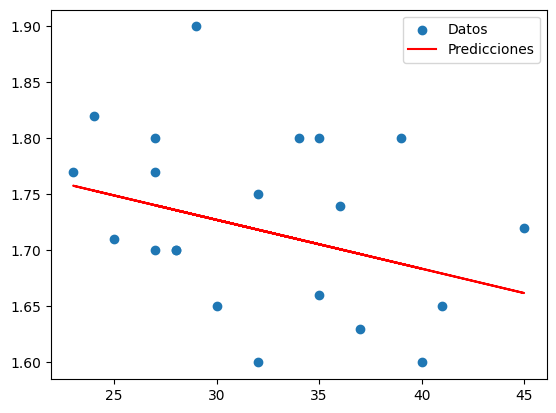

,Edad,prediccion,valor_real,error,error_cuad
0,24,1.753478,1.82,0.066522,0.004425
17,34,1.709906,1.80,0.090094,0.008117
15,32,1.718621,1.75,0.031379,0.000985
1,25,1.749121,1.71,0.039121,0.001530
8,36,1.701192,1.74,0.038808,0.001506


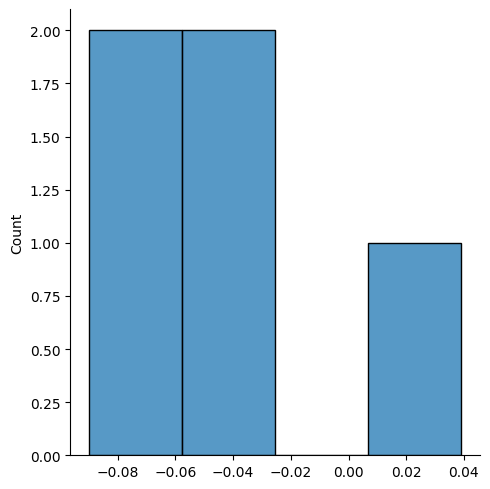